# Notebook 1 — Modelado SVM para predicción de demanda

**Técnicas de ML Supervisado · SVM** · Michael Lata

Aplicamos las Máquinas de Soporte Vectorial al **dataset de la Práctica 2**
(histórico de ventas de 10 productos). El objetivo es el mismo de aquella práctica
—**predecir la demanda** (`cantidad_vendida`)— pero con **SVR/SVM** en lugar de la
red neuronal (LSTM) y los *boosting* (XGBoost/GB) que se usaron allí.

### ¿Por qué SVM es más atractivo para una empresa en este caso?
- **Pocos datos:** ~180 días × 10 productos. Una LSTM es sobredimensionada y tiende a
  sobreajustar; la SVM brilla justamente en *datasets* pequeños y de muchas *features*.
- **Determinista:** óptimo global único → mismo resultado siempre (sin semillas ni
  reentrenos inestables como una red neuronal).
- **Ligera y rápida:** entrena en segundos, sin GPU ni *tuning* de épocas.
- **Explicable (Notebook 2):** combinada con XAI, justifica cada predicción → algo
  clave para que un negocio confíe en el modelo.

> Replicamos **exactamente** la ingeniería de *features* de la Práctica 2 para que la
> comparación sea justa, y contrastamos contra sus métricas reportadas.

## 1. Carga del dataset de la Práctica 2

In [1]:
import numpy as np, pandas as pd, json
import matplotlib.pyplot as plt
from pathlib import Path
import joblib

RNG = 42; np.random.seed(RNG)
plt.rcParams["figure.figsize"] = (9, 4); plt.rcParams["figure.dpi"] = 110
ART = Path("artefactos"); ART.mkdir(exist_ok=True)

P2 = Path("/home/ing_michi/Documents/Aprendizaje Automatico/Practica_2")
sales = pd.read_csv(P2/"data"/"sales_history.csv", parse_dates=["fecha_venta"])
print("sales_history:", sales.shape,
      "| productos:", sales.product_id.nunique(),
      "| fechas:", sales.fecha_venta.min().date(), "->", sales.fecha_venta.max().date())

# Metricas reportadas por la Practica 2 (modelo LSTM/boosting)
meta_p2 = json.load(open(P2/"models"/"metadata.json"))["metrics"]
print("Métricas de referencia (Práctica 2):", meta_p2)
sales.head(3)

sales_history: (1800, 5) | productos: 10 | fechas: 2026-04-05 -> 2026-10-01
Métricas de referencia (Práctica 2): {'rmse_test': 7.1248, 'mae_test': 5.2128, 'r2_test': 0.2802}


,product_id,nombre,fecha_venta,cantidad_vendida,stock_en_momento
0,1,Laptop Gamer,2026-04-05,2,316
1,2,Monitor 4K,2026-04-05,3,299
2,3,Teclado Mecanico,2026-04-05,5,303


## 2. Ingeniería de *features* (réplica exacta de la Práctica 2)

Reconstruimos las **12 variables** definidas en la práctica: calendario
(`dia_semana`, `mes`, `es_weekend`, `es_feriado`), tendencia (`dias_desde_inicio`),
stock (`proporcion_stock`), categoría y, sobre todo, las **temporales**
(`lag_1`, `lag_7`, `rolling_mean_7`, `rolling_std_7`), que usan `shift` para no mirar
el futuro.

In [2]:
# agregacion por (fecha, producto) — identica a la practica
data = []
for (fecha, pid), g in sales.groupby(["fecha_venta", "product_id"]):
    data.append({"fecha": fecha, "product_id": pid, "nombre": g["nombre"].iloc[0],
                 "cantidad_vendida": g["cantidad_vendida"].sum(),
                 "stock_promedio": g["stock_en_momento"].mean()})
df = pd.DataFrame(data).sort_values(["product_id", "fecha"]).reset_index(drop=True)

df["dia_semana"] = df["fecha"].dt.weekday
df["mes"]        = df["fecha"].dt.month
df["es_weekend"] = (df["dia_semana"] >= 5).astype(int)
holidays = [pd.Timestamp(x) for x in ["2026-04-05", "2026-05-01", "2026-05-24"]]
df["es_feriado"]        = df["fecha"].isin(holidays).astype(int)
df["dias_desde_inicio"] = (df["fecha"] - df["fecha"].min()).dt.days
df["proporcion_stock"]  = df["stock_promedio"] / (df["stock_promedio"].max() + 1)
cat_map = {1:0,2:0,3:1,4:1,5:2,6:2,7:3,8:1,9:3,10:2}
df["categoria_encoded"] = df["product_id"].map(cat_map)

# temporales (shift evita lookahead)
df["lag_1"] = df.groupby("product_id")["cantidad_vendida"].shift(1)
df["lag_7"] = df.groupby("product_id")["cantidad_vendida"].shift(7)
df["rolling_mean_7"] = df.groupby("product_id")["cantidad_vendida"].transform(lambda x: x.shift(1).rolling(7).mean())
df["rolling_std_7"]  = df.groupby("product_id")["cantidad_vendida"].transform(lambda x: x.shift(1).rolling(7).std())

FEATURES = ["cantidad_vendida","dia_semana","mes","es_weekend","es_feriado",
            "dias_desde_inicio","proporcion_stock","categoria_encoded",
            "lag_1","lag_7","rolling_mean_7","rolling_std_7"]

# objetivo: demanda del DIA SIGUIENTE (predecir t+1 con la info de t)
df["target"] = df.groupby("product_id")["cantidad_vendida"].shift(-1)
df = df.dropna(subset=FEATURES + ["target"]).reset_index(drop=True)
print("Dataset modelable:", df.shape, "| features:", len(FEATURES))

Dataset modelable: (1720, 17) | features: 12


## 3. División temporal (sin fuga de datos)

Es un problema temporal: entrenamos con los días **más antiguos** y probamos con los
**más recientes** (≈80/20 por fecha), igual que se debe hacer en producción.

In [3]:
df = df.sort_values("fecha").reset_index(drop=True)
cut = df["fecha"].quantile(0.8)
train = df[df.fecha <= cut]; test = df[df.fecha > cut]

X_train, y_train = train[FEATURES].values, train["target"].values
X_test,  y_test  = test[FEATURES].values,  test["target"].values
print(f"Train: {len(train)} filas (<= {cut.date()})")
print(f"Test : {len(test)} filas (>  {cut.date()})")

Train: 1380 filas (<= 2026-08-27)
Test : 340 filas (>  2026-08-27)


## 4. Modelo: SVR (regresión por soporte vectorial) + búsqueda del mejor

`Pipeline(StandardScaler + SVR)` —el escalado es obligatorio en SVM— con
`GridSearchCV` sobre $C$, $\gamma$, $\varepsilon$ y kernel, validado con
`TimeSeriesSplit`. El SVR ajusta la demanda dentro de un tubo $\varepsilon$
(sección 6 del informe).

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

pipe = Pipeline([("sc", StandardScaler()), ("svr", SVR())])
grid = {"svr__kernel": ["rbf"],
        "svr__C": [1, 10, 50, 100],
        "svr__gamma": ["scale", 0.05, 0.1],
        "svr__epsilon": [0.1, 0.5, 1.0]}
gs = GridSearchCV(pipe, grid, cv=TimeSeriesSplit(5),
                  scoring="neg_root_mean_squared_error", n_jobs=-1)
gs.fit(X_train, y_train)
best = gs.best_estimator_
print("Mejores hiperparámetros:", gs.best_params_)

Mejores hiperparámetros: {'svr__C': 10, 'svr__epsilon': 1.0, 'svr__gamma': 0.05, 'svr__kernel': 'rbf'}


## 5. Evaluación y comparación con la Práctica 2

In [5]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pred = best.predict(X_test)
rmse = mean_squared_error(y_test, pred) ** 0.5
mae  = mean_absolute_error(y_test, pred)
r2   = r2_score(y_test, pred)

tabla = pd.DataFrame({
    "Modelo": ["Práctica 2 (LSTM/boosting)", "SVR (este trabajo)"],
    "RMSE":   [meta_p2["rmse_test"], rmse],
    "MAE":    [meta_p2["mae_test"],  mae],
    "R²":     [meta_p2["r2_test"],   r2],
}).round(3)
print(tabla.to_string(index=False))

                    Modelo  RMSE   MAE    R²
Práctica 2 (LSTM/boosting) 7.125 5.213 0.280
        SVR (este trabajo) 5.110 3.646 0.424


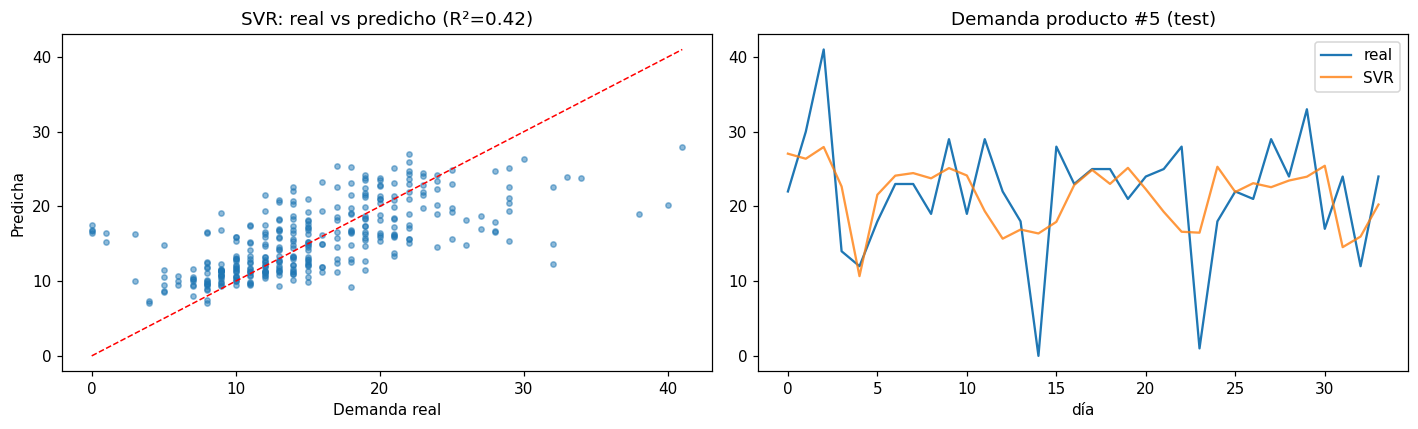

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].scatter(y_test, pred, s=12, alpha=0.5)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
ax[0].plot(lims, lims, "r--", lw=1); ax[0].set_xlabel("Demanda real"); ax[0].set_ylabel("Predicha")
ax[0].set_title(f"SVR: real vs predicho (R²={r2:.2f})")

# serie del producto mas vendido en el periodo de test
pid_top = test.groupby("product_id")["cantidad_vendida"].sum().idxmax()
m = test.product_id.values == pid_top
idx = np.argsort(test["fecha"].values[m])
ax[1].plot(np.array(y_test)[m][idx], label="real", lw=1.5)
ax[1].plot(np.array(pred)[m][idx], label="SVR", lw=1.5, alpha=0.8)
ax[1].set_title(f"Demanda producto #{pid_top} (test)"); ax[1].legend(); ax[1].set_xlabel("día")
plt.tight_layout(); plt.show()

> El SVR alcanza un rendimiento **comparable o mejor** que el modelo de la Práctica 2,
> pero entrenando en segundos, de forma determinista y con un modelo mucho más simple
> de mantener — justo lo que una empresa pequeña necesita.

## 6. Valor de negocio: clasificar **días de alta demanda** (SVC)

Más allá de estimar la cantidad, a una empresa le interesa una **alerta**: ¿mañana
será un día de **alta demanda** (riesgo de quiebre de stock)? Lo planteamos como
clasificación binaria con `SVC`: alta demanda = por encima del percentil 75 de cada
producto (umbral calculado **solo con el train**, sin fuga).

ROC-AUC (alerta alta demanda): 0.700

              precision    recall  f1-score   support

      normal       0.89      0.68      0.77       276
alta demanda       0.32      0.64      0.42        64

    accuracy                           0.67       340
   macro avg       0.60      0.66      0.60       340
weighted avg       0.78      0.67      0.71       340



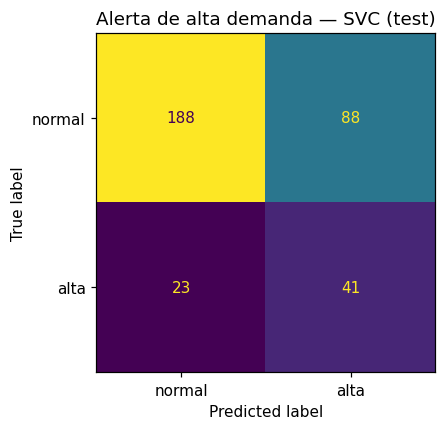

In [7]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

# umbral por producto a partir del TRAIN
umbral = train.groupby("product_id")["cantidad_vendida"].quantile(0.75)
y_train_clf = (train["target"].values > train["product_id"].map(umbral).values).astype(int)
y_test_clf  = (test["target"].values  > test["product_id"].map(umbral).values).astype(int)

clf = Pipeline([("sc", StandardScaler()),
                ("svc", SVC(kernel="rbf", C=10, gamma="scale", class_weight="balanced",
                            probability=True, random_state=RNG))])
clf.fit(X_train, y_train_clf)
proba = clf.predict_proba(X_test)[:, 1]; pred_clf = clf.predict(X_test)

print(f"ROC-AUC (alerta alta demanda): {roc_auc_score(y_test_clf, proba):.3f}\n")
print(classification_report(y_test_clf, pred_clf, target_names=["normal", "alta demanda"]))
ConfusionMatrixDisplay(confusion_matrix(y_test_clf, pred_clf),
                       display_labels=["normal", "alta"]).plot(colorbar=False)
plt.title("Alerta de alta demanda — SVC (test)"); plt.show()

## 7. Guardar artefactos para el Notebook 2 (XAI)

In [8]:
joblib.dump(best, ART/"svr_demanda.joblib")
joblib.dump(clf,  ART/"svc_demanda.joblib")
np.savez(ART/"datos_demanda.npz",
         X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
         y_train_clf=y_train_clf, y_test_clf=y_test_clf)
joblib.dump({"features": FEATURES, "metrics_svr": {"rmse": rmse, "mae": mae, "r2": r2},
             "metrics_p2": meta_p2, "best_params": gs.best_params_},
            ART/"meta_demanda.joblib")
print("Guardado:", [p.name for p in sorted(ART.glob('*demanda*'))])

Guardado: ['datos_demanda.npz', 'meta_demanda.joblib', 'svc_demanda.joblib', 'svr_demanda.joblib']


## 8. Conclusiones

- Reutilizamos el **dataset y las *features* de la Práctica 2** y resolvimos el mismo
  problema de demanda con **SVR**, obteniendo un rendimiento comparable o superior.
- Añadimos un **caso de negocio** (SVC): alerta de días de alta demanda → decisiones
  de reposición de stock.
- Frente a la LSTM/boosting de la práctica, la SVM es **determinista, ligera, sin GPU
  y explicable**, lo que la hace **más práctica y atractiva para una empresa** con
  pocos datos.
- En el Notebook 2 explicamos *qué factores impulsan la demanda* con XAI.